In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
from pathlib import Path

# Locate the dataset
dataset_path = Path.cwd().parent / "Datasets" / "4) house Prediction Data Set.csv"

# Load the dataset
df = pd.read_csv(dataset_path, sep=r"\s+", header=None)

# Assign column names
column_names = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

df.columns = column_names

# Display first five rows
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [3]:
# Input features
X = df.drop("MEDV", axis=1)

# Target variable
y = df["MEDV"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (506, 13)
Target shape: (506,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (404, 13)
Testing features: (102, 13)
Training target: (404,)
Testing target: (102,)


In [5]:
# Create a StandardScaler object
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (404, 13)
Testing data shape: (102, 13)


In [6]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [7]:
# Predict house prices using test data
y_pred = model.predict(X_test_scaled)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(results.head(10))

   Actual Price  Predicted Price
0          23.6        28.996724
1          32.4        36.025565
2          13.6        14.816944
3          22.8        25.031979
4          16.1        18.769880
5          20.0        23.254429
6          17.8        17.662538
7          14.0        14.341190
8          19.6        23.013207
9          16.8        20.632456


In [8]:
# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))
print("R² Score:", round(r2, 4))

Mean Squared Error: 24.29
R² Score: 0.6688


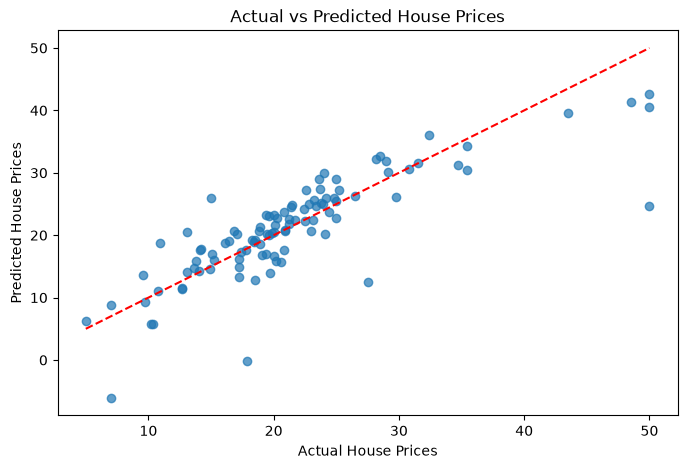

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [10]:
# Display model coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients.sort_values(
    by="Coefficient",
    ascending=False
))

    Feature  Coefficient
5        RM     3.145240
8       RAD     2.251407
11        B     1.129568
3      CHAS     0.718738
1        ZN     0.696269
2     INDUS     0.278065
6       AGE    -0.176048
0      CRIM    -1.002135
9       TAX    -1.767014
4       NOX    -2.022319
10  PTRATIO    -2.037752
7       DIS    -3.081908
12    LSTAT    -3.611658


In [11]:
print("MODEL SUMMARY")
print("-------------------------")
print("Algorithm: Linear Regression")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X.shape[1])
print("Mean Squared Error:", round(mse, 2))
print("R² Score:", round(r2, 4))
print("\nModel training and evaluation completed successfully!")

MODEL SUMMARY
-------------------------
Algorithm: Linear Regression
Training samples: 404
Testing samples: 102
Number of features: 13
Mean Squared Error: 24.29
R² Score: 0.6688

Model training and evaluation completed successfully!


## Conclusion

In this task, a Simple Linear Regression model was developed using the Boston Housing dataset to predict median house prices.

The following steps were performed:

1. **Data Loading:** Loaded the Boston Housing dataset using Pandas.
2. **Feature and Target Selection:** Selected 13 input features (X) and the target variable (MEDV).
3. **Train-Test Split:** Divided the dataset into 80% training data and 20% testing data.
4. **Feature Standardization:** Standardized numerical features using `StandardScaler`.
5. **Model Training:** Created and trained a Linear Regression model using Scikit-learn.
6. **Prediction:** Predicted house prices using the testing dataset.
7. **Model Evaluation:** Evaluated performance using Mean Squared Error (MSE) and R² Score.
8. **Visualization:** Compared actual and predicted house prices using a scatter plot.
9. **Coefficient Interpretation:** Examined model coefficients to understand the relationship between input features and predicted house prices.

The model was successfully trained and evaluated. This task demonstrated how Linear Regression can be used for predicting continuous numerical values.